## Nama : Muh. Zulfan Azima
## NIM : H061241056


## 1. Import Modul

Library yang digunakan dibuat sederhana agar notebook mudah dijalankan di Jupyter Notebook, JupyterLab, maupun VS Code.

- `numpy` → komputasi numerik
- `pandas` → pengelolaan data tabular dan time series
- `matplotlib` → visualisasi
- `scipy.special` → solusi analitik difusi panas untuk verification


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import erfc
from pathlib import Path

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["font.size"] = 11

rng = np.random.default_rng(42)
print("Environment siap.")


Environment siap.



# Recipe 1 — R-IO-001: Membaca dan Merangkum Station CSV

### Problem
Data pengamatan sering berada dalam CSV. Sebelum melakukan analisis, struktur file, jumlah data, missing value, dan ringkasan per stasiun perlu diperiksa.

Contoh berikut membuat **fixture sintetis** dengan kolom `station_id`, `timestamp`, dan `rainfall_mm`, lalu membaca kembali file tersebut.


In [2]:

# Membuat fixture CSV sintetis
dates = pd.date_range("2026-01-01", periods=365, freq="D")
station_ids = ["STA01", "STA02", "STA03"]
frames = []

for station, phase in zip(station_ids, [0.0, 0.7, 1.3]):
    seasonal = 6 + 4 * np.sin(2 * np.pi * np.arange(365) / 365 + phase)
    wet_signal = 5 * np.maximum(
        0, np.sin(2 * np.pi * np.arange(365) / 90 + phase)
    )
    noise = rng.normal(0, 1.5, 365)
    rainfall = np.clip(seasonal + wet_signal + noise, 0, None)

    frames.append(pd.DataFrame({
        "station_id": station,
        "timestamp": dates,
        "rainfall_mm": rainfall
    }))

station_df = pd.concat(frames, ignore_index=True)

# Missing value untuk demonstrasi QA/QC
missing_idx = rng.choice(station_df.index, size=12, replace=False)
station_df.loc[missing_idx, "rainfall_mm"] = np.nan

csv_path = Path("synthetic_station_rainfall.csv")
station_df.to_csv(csv_path, index=False)

print(f"CSV dibuat: {csv_path}")
station_df.head()


CSV dibuat: synthetic_station_rainfall.csv


,station_id,timestamp,rainfall_mm
0,STA01,2026-01-01,6.457076
1,STA01,2026-01-02,4.857660
2,STA01,2026-01-03,7.959229
3,STA01,2026-01-04,8.656884
4,STA01,2026-01-05,4.726844


In [3]:

# Membaca kembali CSV
df = pd.read_csv(csv_path, parse_dates=["timestamp"])

print("Ukuran data :", df.shape)
print("Kolom       :", list(df.columns))

print("\nMissing value:")
print(df.isna().sum())

print("\nJumlah observasi per station:")
print(df.groupby("station_id").size())

summary_station = (
    df.groupby("station_id")["rainfall_mm"]
      .agg(["count", "mean", "std", "min", "max"])
      .round(2)
)

summary_station


Ukuran data : (1095, 3)
Kolom       : ['station_id', 'timestamp', 'rainfall_mm']

Missing value:
station_id      0
timestamp       0
rainfall_mm    12
dtype: int64

Jumlah observasi per station:
station_id
STA01    365
STA02    365
STA03    365
dtype: int64


,count,mean,std,min,max
station_id,,,,,
STA01,358,7.52,3.61,0.0,16.62
STA02,364,7.50,3.83,0.0,17.48
STA03,361,7.64,3.80,0.0,16.16



### Visualisasi inspection

Plot ini digunakan untuk memeriksa pola umum data dan kemungkinan gap. Plot belum dipakai untuk membuat claim geofisika.


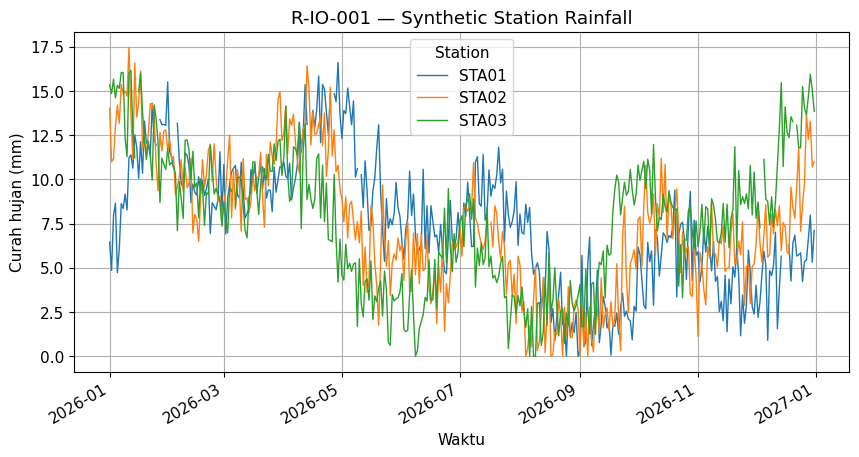

In [4]:

fig, ax = plt.subplots()

for station, group in df.groupby("station_id"):
    ax.plot(
        group["timestamp"],
        group["rainfall_mm"],
        linewidth=1,
        label=station
    )

ax.set_title("R-IO-001 — Synthetic Station Rainfall")
ax.set_xlabel("Waktu")
ax.set_ylabel("Curah hujan (mm)")
ax.legend(title="Station")

fig.autofmt_xdate()
plt.show()
